In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

# Set random seeds for reproducibility
SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

# Define dataset paths (adjust if your local path differs)
# The Intel Image Classification dataset typically extracts into 'seg_train', 'seg_test', and 'seg_pred'
DATASET_DIR = './'  # Change to your folder path if needed
TRAIN_DIR = os.path.join(DATASET_DIR, 'seg_train/seg_train')
TEST_DIR = os.path.join(DATASET_DIR, 'seg_test/seg_test')

# Inspect classes and count samples per class
classes = sorted(os.listdir(TRAIN_DIR))
print(f"Detected Classes ({len(classes)}): {classes}\n")

print("--- Training Samples per Class ---")
for cls in classes:
    cls_path = os.path.join(TRAIN_DIR, cls)
    if os.path.isdir(cls_path):
        print(f"{cls:12s}: {len(os.listdir(cls_path))} images")

Detected Classes (6): ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

--- Training Samples per Class ---
buildings   : 2191 images
forest      : 2271 images
glacier     : 2404 images
mountain    : 2512 images
sea         : 2274 images
street      : 2382 images


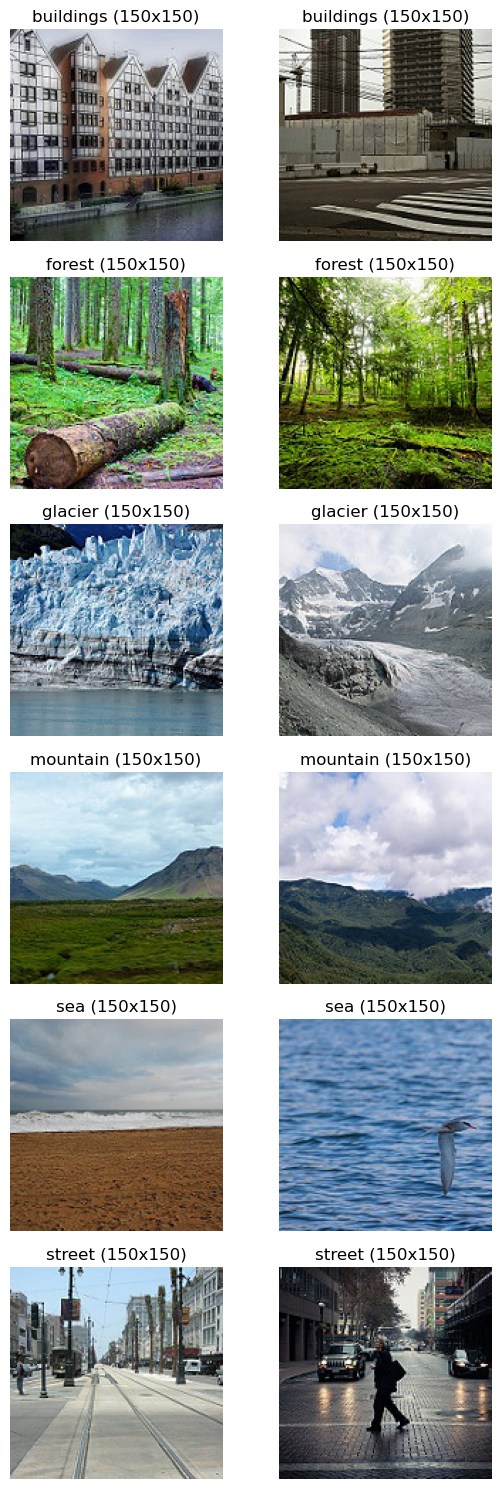

In [2]:
# Visualize 2 sample images from each class
fig, axes = plt.subplots(len(classes), 2, figsize=(6, 15))

for idx, cls in enumerate(classes):
    cls_path = os.path.join(TRAIN_DIR, cls)
    sample_files = random.sample(os.listdir(cls_path), 2)
    
    for col_idx, file_name in enumerate(sample_files):
        img_path = os.path.join(cls_path, file_name)
        img = Image.open(img_path)
        
        ax = axes[idx, col_idx]
        ax.imshow(img)
        ax.set_title(f"{cls} ({img.size[0]}x{img.size[1]})")
        ax.axis('off')

plt.tight_layout()
plt.show()

In [3]:
# Image dimensions and training batch configurations
IMG_HEIGHT = 150
IMG_WIDTH = 150
BATCH_SIZE = 32

# 1. Load Training Dataset (80% split)
train_raw_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

# 2. Load Validation Dataset (20% split)
val_raw_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

# 3. Load Test Dataset
test_raw_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    shuffle=False,  # Keep un-shuffled for accurate evaluation metrics later
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

class_names = train_raw_ds.class_names
print(f"\nClass Names: {class_names}")

# 4. Define Data Augmentation & Normalization Layers
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(height_factor=0.1, width_factor=0.1)
], name="data_augmentation")

normalization_layer = layers.Rescaling(1./255)

# 5. Build an optimized pipeline using tf.data
AUTOTUNE = tf.data.AUTOTUNE

# Apply augmentation + normalization to training data
train_ds = train_raw_ds.map(
    lambda x, y: (normalization_layer(data_augmentation(x, training=True)), y),
    num_parallel_calls=AUTOTUNE
).prefetch(buffer_size=AUTOTUNE)

# Only normalize validation & test data (never augment evaluation sets)
val_ds = val_raw_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=AUTOTUNE
).prefetch(buffer_size=AUTOTUNE)

test_ds = test_raw_ds.map(
    lambda x, y: (normalization_layer(x), y),
    num_parallel_calls=AUTOTUNE
).prefetch(buffer_size=AUTOTUNE)

print("Data preprocessing and pipelines configured successfully.")

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.

Class Names: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Data preprocessing and pipelines configured successfully.


In [4]:
num_classes = len(class_names)

model = keras.Sequential([
    # Input shape: 150x150 RGB images
    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    
    # Conv Block 1
    layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Conv Block 2
    layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Conv Block 3
    layers.Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Conv Block 4 (Optional deeper feature extraction)
    layers.Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),
    
    # Dense Classifier Head
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),  # Regularization to prevent overfitting
    layers.Dense(num_classes, activation='softmax')  # 6 output classes
], name="Intel_Scene_CNN")

# Display the model summary
model.summary()

Model: "Intel_Scene_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 18, 18, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,654,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,898,246 (11.06 MB)

 Trainable params: 2,897,542 (11.05 MB)

 Non-trainable params: 704 (2.75 KB)

In [5]:
# 1. Compile the Model
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 2. Setup Callbacks
callbacks = [
    # Stop training if validation loss does not improve for 5 consecutive epochs
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    # Save the model with the highest validation accuracy
    keras.callbacks.ModelCheckpoint(
        filepath='best_intel_cnn_model.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    # Dynamically reduce learning rate when progress plateaus
    keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

# 3. Train the Model
EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/20


C:\Users\kitch\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 309ms/step - accuracy: 0.4881 - loss: 1.5976
Epoch 1: val_accuracy improved from None to 0.44476, saving model to best_intel_cnn_model.keras

Epoch 1: finished saving model to best_intel_cnn_model.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 116s 323ms/step - accuracy: 0.4881 - loss: 1.5976 - val_accuracy: 0.4448 - val_loss: 1.7618 - learning_rate: 0.0010
Epoch 2/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 0.5673 - loss: 1.1450
Epoch 2: val_accuracy improved from 0.44476 to 0.54170, saving model to best_intel_cnn_model.keras

Epoch 2: finished saving model to best_intel_cnn_model.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 113s 321ms/step - accuracy: 0.5673 - loss: 1.1450 - val_accuracy: 0.5417 - val_loss: 1.4538 - learning_rate: 0.0010
Epoch 3/20
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step - accuracy: 0.6268 - loss: 1.0194
Epoch 3: val_accuracy improved from 0.54170 to 0.61440, saving model to best_intel_cnn_model.keras

Epoch 3: finished saving model to best

94/94 ━━━━━━━━━━━━━━━━━━━━ 8s 79ms/step - accuracy: 0.7877 - loss: 0.6635

Final Test Loss:     0.6635
Final Test Accuracy: 78.77%

             CLASSIFICATION REPORT
              precision    recall  f1-score   support

   buildings     0.7036    0.8146    0.7550       437
      forest     0.9759    0.9409    0.9581       474
     glacier     0.8448    0.6203    0.7153       553
    mountain     0.8739    0.5943    0.7075       525
         sea     0.6373    0.8922    0.7435       510
      street     0.8054    0.9002    0.8501       501

    accuracy                         0.7877      3000
   macro avg     0.8068    0.7937    0.7883      3000
weighted avg     0.8082    0.7877    0.7854      3000



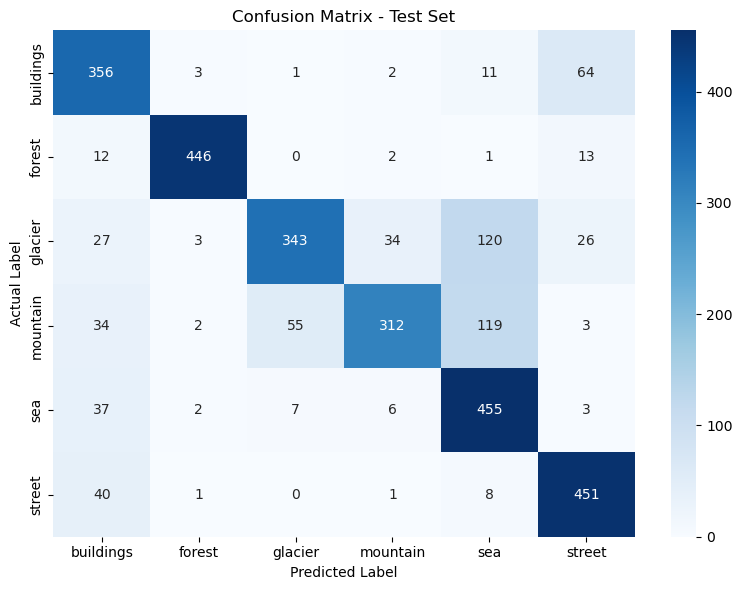

In [6]:
# 1. Evaluate Overall Test Loss and Accuracy
test_loss, test_accuracy = model.evaluate(test_ds)
print(f"\nFinal Test Loss:     {test_loss:.4f}")
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%\n")

# 2. Generate Predictions Across the Entire Test Set
# Extract ground-truth labels and model predictions
y_true = []
y_pred_probs = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred_probs.extend(preds)
    y_true.extend(np.argmax(labels.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.argmax(np.array(y_pred_probs), axis=1)

# 3. Precision, Recall, and F1-Score per Class
print("=" * 60)
print("             CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# 4. Confusion Matrix Heatmap
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title('Confusion Matrix - Test Set')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

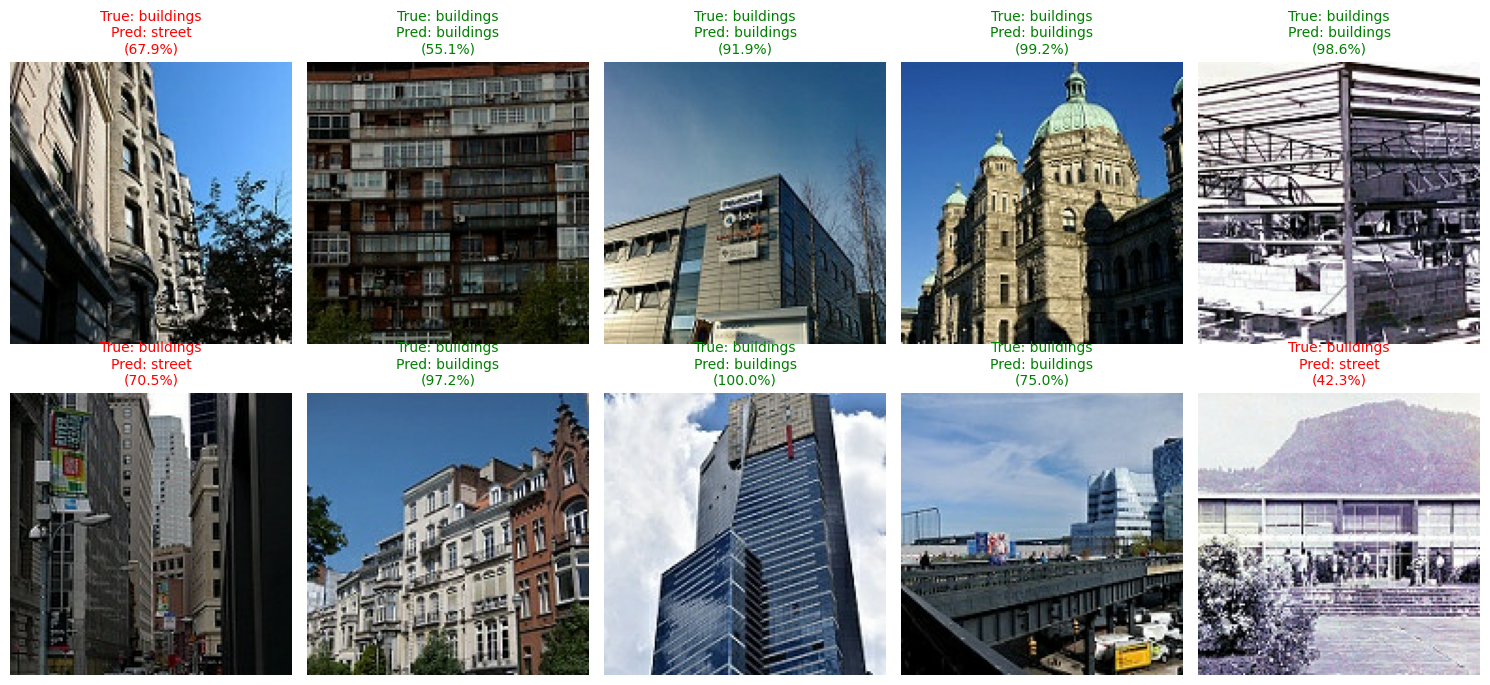

In [7]:
# Load unbatched test samples for clean image visualization
raw_test_images = []
raw_test_labels = []

# Fetch a couple of raw batches from test_raw_ds
for imgs, lbls in test_raw_ds.take(2):
    raw_test_images.extend(imgs.numpy().astype("uint8"))
    raw_test_labels.extend(np.argmax(lbls.numpy(), axis=1))

# Select 10 random sample indices
random_indices = random.sample(range(len(raw_test_images)), 10)

plt.figure(figsize=(15, 7))

for i, idx in enumerate(random_indices):
    img = raw_test_images[idx]
    actual_lbl = class_names[raw_test_labels[idx]]
    
    # Preprocess single image for prediction
    img_array = np.expand_dims(img, axis=0) / 255.0
    pred_probs = model.predict(img_array, verbose=0)[0]
    pred_idx = np.argmax(pred_probs)
    pred_lbl = class_names[pred_idx]
    confidence = pred_probs[pred_idx] * 100
    
    # Plot image with color-coded title (Green if correct, Red if misclassified)
    ax = plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    color = 'green' if pred_lbl == actual_lbl else 'red'
    ax.set_title(f"True: {actual_lbl}\nPred: {pred_lbl}\n({confidence:.1f}%)", color=color, fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()